In [1]:
pip install faiss-cpu mlflow scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings('ignore')

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# TF-IDF Embeddings (no download needed)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# FAISS Vector Index
import faiss

# MLflow
import mlflow

print('✅ All imports successful!')
print('   sklearn  : TF-IDF embeddings')
print('   faiss    : vector index')
print('   mlflow   : experiment tracking')

✅ All imports successful!
   sklearn  : TF-IDF embeddings
   faiss    : vector index
   mlflow   : experiment tracking


In [3]:
os.makedirs('knowledge_base', exist_ok=True)

documents = {

'faq_general.txt': """FREQUENTLY ASKED QUESTIONS — GENERAL SUPPORT

Q1: How do I track my order?
A: Log into your account, go to My Orders, and click Track next to your order.
You will receive a tracking number via email within 24 hours of shipment.

Q2: How long does delivery take?
A: Standard delivery takes 5-7 business days. Express delivery takes 1-2 business days.
International orders may take 10-15 business days.

Q3: Can I change my delivery address after placing an order?
A: Address changes are allowed within 2 hours of placing the order.
Contact support immediately at support@company.com or call 1800-XXX-XXXX.

Q4: What payment methods are accepted?
A: We accept Visa, Mastercard, American Express, PayPal, UPI, Net Banking, and EMI options.

Q5: How do I cancel an order?
A: Orders can be cancelled within 24 hours of placement via My Orders page.
After 24 hours, cancellation is not guaranteed if the item has been shipped.

Q6: How do I contact customer support?
A: Email support@company.com, Chat 9AM to 9PM IST, or call 1800-XXX-XXXX toll-free 24x7.""",

'refund_policy.txt': """REFUND AND RETURN POLICY

1. RETURN WINDOW
Electronics: 7 days from delivery date. Clothing: 30 days from delivery date.
Perishables and digital products are non-returnable.

2. CONDITIONS FOR RETURN
Item must be unused and in original packaging with all accessories and invoice.
Items with customer-caused physical damage are not eligible.

3. REFUND PROCESS
Refunds are processed within 5-7 business days after return inspection.
Refund is credited to the original payment method.
Cash on Delivery orders receive refund via bank transfer or store credit.

4. HOW TO INITIATE A RETURN
Step 1: Go to My Orders and click Return or Refund.
Step 2: Choose return reason and upload photos if required.
Step 3: Schedule a pickup or drop off at nearest service centre.

5. DAMAGED OR DEFECTIVE ITEMS
Report within 48 hours of delivery with photos.
Replacement or full refund processed within 3-5 business days.
Priority handling for Platinum and Gold tier customers.

6. ESCALATION
If refund not received within 10 business days, escalate to refunds@company.com.
Include Order ID, Return ID, and bank details in escalation email.""",

'troubleshooting_guide.txt': """TECHNICAL TROUBLESHOOTING GUIDE

SECTION 1: WIFI CONNECTIVITY ISSUES
Problem: Device not connecting to WiFi.
Steps: Restart device and router. Forget and reconnect WiFi network.
Check if other devices connect. Update firmware. Reset network settings.
Contact support with device model if issue persists.

SECTION 2: DEVICE NOT TURNING ON
Problem: Device completely unresponsive.
Steps: Charge device for 30 minutes. Perform hard reset by holding Power and Volume Down for 10 seconds.
Check charging port for damage. Try different cable and adapter.
If under warranty raise a replacement request immediately.

SECTION 3: APPLICATION CRASHES
Problem: App crashes on launch.
Steps: Force close and relaunch. Clear app cache in Settings.
Update app from app store. Uninstall and reinstall application.
Ensure at least 1 GB free storage space available.

SECTION 4: BATTERY DRAINS QUICKLY
Problem: Battery drains within short time.
Steps: Check battery usage in Settings. Disable background app refresh.
Reduce screen brightness and timeout. Disable location services.
If battery health below 80 percent apply for warranty battery replacement.

SECTION 5: SCREEN FLICKERING
Problem: Screen flickering or display issues.
Steps: Adjust brightness. Disable auto brightness. Update firmware.
Boot in safe mode to check third party apps. Book service centre if hardware issue.""",

'warranty_policy.txt': """WARRANTY POLICY

1. WARRANTY COVERAGE
All electronics carry a standard 1-year manufacturer warranty.
Extended warranty plans available for 2 and 3 years.
Warranty covers manufacturing defects and hardware failures.
Warranty does NOT cover physical damage, water damage, or unauthorised repairs.

2. WARRANTY CLAIM PROCESS
Step 1: Visit warranty.company.com and enter product serial number.
Step 2: Describe the defect and upload supporting photos or videos.
Step 3: Receive a Warranty Reference Number via email.
Step 4: Ship product to nearest service centre using provided label.
Step 5: Repair or replacement completed within 7-10 business days.

3. ON-SITE WARRANTY FOR PLATINUM CUSTOMERS
Platinum tier customers receive on-site warranty service.
A technician visits within 24 hours of warranty claim approval.
Applies to products above Rs 50000 in value.

4. VOIDING WARRANTY
Warranty is voided if device is opened by unauthorised personnel.
Rooting or jailbreaking voids warranty.
Physical damage including cracked screens voids warranty.""",

'escalation_sop.txt': """ESCALATION STANDARD OPERATING PROCEDURE

1. ESCALATION TRIGGERS
Escalate when no resolution after 3 agent interactions.
Customer explicitly requests supervisor.
Ticket open more than 48 hours without resolution.
Platinum or Gold customer with unresolved Critical ticket.
Legal threat or social media complaint received.
Refund amount exceeds Rs 10000.

2. ESCALATION LEVELS
Level 1: Senior Support Agent.
Level 2: Support Team Lead.
Level 3: Support Manager.
Level 4: Director of Customer Experience for legal or media cases.

3. ESCALATION PROCEDURE
Step 1: Document all previous interactions in the ticket.
Step 2: Tag ticket as Escalated in CRM system.
Step 3: Assign to next level using assignment queue.
Step 4: Notify customer via email that ticket has been escalated.
SLA timers: Level 1 equals 4 hours, Level 2 equals 8 hours, Level 3 equals 24 hours.

4. PLATINUM CUSTOMER ESCALATION
Platinum customers skip Level 1 and go directly to Level 2.
Dedicated account manager notified via Slack immediately.
Compensation offer pre-approved up to Rs 2000.""",

'account_billing_faq.txt': """ACCOUNT AND BILLING FAQ

Q1: I was charged twice for my order. What should I do?
A: Check bank statement for duplicate transaction IDs.
Email billing@company.com with Order ID and transaction IDs.
Duplicate charge reversed within 3-5 business days.

Q2: My account is locked. How do I unlock it?
A: Accounts are locked after 5 failed login attempts.
Click Forgot Password on login page and follow reset link.
If email not received within 5 minutes check spam folder.

Q3: How do I view my invoice?
A: Go to My Orders, select order, and click Download Invoice PDF.
Invoices are also emailed automatically after each purchase.

Q4: What is the loyalty tier system?
A: Bronze 0 to 999 points, Silver 1000 to 4999, Gold 5000 to 9999, Platinum 10000 plus.
Points earned at 1 point per Rs 10 spent.
Platinum members get priority support, free express delivery, and exclusive discounts.

Q5: How do I apply a promo code?
A: Enter promo code at checkout in Apply Coupon field.
Only one promo code per order. Cannot be combined with other offers.""",

'internal_resolution_notes.txt': """INTERNAL RESOLUTION NOTES

CASE: Duplicate Payment
Verify via payment gateway dashboard.
Initiate reversal from Finance portal under Refunds and Duplicate Transactions.
Timeline 3-5 business days. Notify customer with reversal reference number.

CASE: Package Not Delivered but Marked Delivered
Check GPS delivery proof in logistics portal.
If no proof found lodge missing package claim with courier.
Reship or refund within 5 business days.

CASE: Device Dead on Arrival
If reported within 48 hours of delivery classify as DOA.
Initiate express replacement from DOA queue in Warehouse portal.
Replacement ships within 24 hours for Platinum and 48 hours for others.

CASE: Wrong Item Delivered
Raise logistics error ticket in Warehouse Management System.
Schedule pickup of wrong item and dispatch correct item simultaneously.
Customer should not return before receiving correct item.

CASE: Refund Not Received After 10 Days
Check refund status in Finance portal.
If status is Processed share bank reference number with customer.
If status is Pending escalate to refunds-escalation@company.com."""
}

for filename, content in documents.items():
    with open(f'knowledge_base/{filename}', 'w', encoding='utf-8') as f:
        f.write(content.strip())

print(f'✅ Created {len(documents)} knowledge base documents in ./knowledge_base/')
for fname in documents:
    print(f'   📄 {fname}')

✅ Created 7 knowledge base documents in ./knowledge_base/
   📄 faq_general.txt
   📄 refund_policy.txt
   📄 troubleshooting_guide.txt
   📄 warranty_policy.txt
   📄 escalation_sop.txt
   📄 account_billing_faq.txt
   📄 internal_resolution_notes.txt


In [4]:
# Load documents from disk
raw_docs = []
for filename in os.listdir('knowledge_base'):
    if filename.endswith('.txt'):
        with open(f'knowledge_base/{filename}', 'r', encoding='utf-8') as f:
            content = f.read()
        raw_docs.append({'source': filename, 'content': content})

print(f'✅ Loaded {len(raw_docs)} documents')
for doc in raw_docs:
    print(f'   📄 {doc["source"]} — {len(doc["content"])} chars')

✅ Loaded 9 documents
   📄 account_billing_faq.txt — 1037 chars
   📄 billing_policy.txt — 140 chars
   📄 escalation_sop.txt — 1057 chars
   📄 faq_general.txt — 1049 chars
   📄 internal_resolution_notes.txt — 1095 chars
   📄 past_resolutions.txt — 142 chars
   📄 refund_policy.txt — 1123 chars
   📄 troubleshooting_guide.txt — 1366 chars
   📄 warranty_policy.txt — 1044 chars


In [5]:
# Chunk each document
def chunk_text(text, chunk_size=400, overlap=50):
    chunks = []
    start  = 0
    while start < len(text):
        end   = min(start + chunk_size, len(text))
        chunk = text[start:end].strip()
        if len(chunk) > 30:
            chunks.append(chunk)
        start += chunk_size - overlap
    return chunks

all_chunks = []
chunk_meta = []

for doc in raw_docs:
    for i, chunk in enumerate(chunk_text(doc['content'])):
        all_chunks.append(chunk)
        chunk_meta.append({'source': doc['source'], 'chunk_id': i})

print(f'✅ Total chunks : {len(all_chunks)}')
print(f'   Avg length  : {sum(len(c) for c in all_chunks)//len(all_chunks)} chars')
print(f'\nSample chunk:\n{"-"*50}')
print(all_chunks[2])

✅ Total chunks : 26
   Avg length  : 342 chars

Sample chunk:
--------------------------------------------------
0 to 4999, Gold 5000 to 9999, Platinum 10000 plus.
Points earned at 1 point per Rs 10 spent.
Platinum members get priority support, free express delivery, and exclusive discounts.

Q5: How do I apply a promo code?
A: Enter promo code at checkout in Apply Coupon field.
Only one promo code per order. Cannot be combined with other offers.


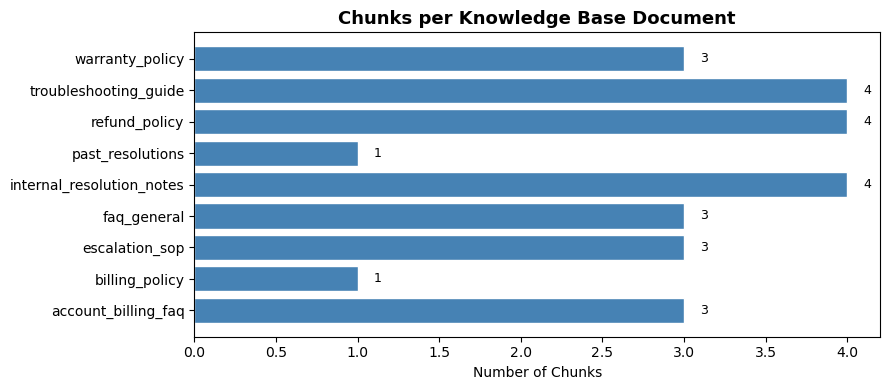

✅ Chart saved → chunk_distribution.png


In [6]:
# Chunk distribution chart
source_counts = Counter(m['source'] for m in chunk_meta)
labels = [k.replace('.txt','') for k in source_counts]
counts = list(source_counts.values())

plt.figure(figsize=(9, 4))
bars = plt.barh(labels, counts, color='steelblue', edgecolor='white')
plt.xlabel('Number of Chunks')
plt.title('Chunks per Knowledge Base Document', fontsize=13, fontweight='bold')
for bar, count in zip(bars, counts):
    plt.text(count + 0.1, bar.get_y() + bar.get_height()/2,
             str(count), va='center', fontsize=9)
plt.tight_layout()
plt.savefig('chunk_distribution.png', dpi=150)
plt.show()
print('✅ Chart saved → chunk_distribution.png')

In [7]:
# Build TF-IDF embeddings for all chunks
print('🔄 Building TF-IDF embeddings...')
start = time.time()

vectorizer       = TfidfVectorizer(max_features=1000, ngram_range=(1,2))
chunk_embeddings = vectorizer.fit_transform(all_chunks).toarray().astype('float32')

elapsed = round(time.time() - start, 3)
print(f'✅ TF-IDF embeddings built in {elapsed}s')
print(f'   Embedding shape : {chunk_embeddings.shape}')
print(f'   Vocabulary size : {len(vectorizer.vocabulary_)}')

🔄 Building TF-IDF embeddings...
✅ TF-IDF embeddings built in 0.043s
   Embedding shape : (26, 1000)
   Vocabulary size : 1000


In [8]:
# Build FAISS index (Inner Product = cosine similarity on L2-normed vectors)
dim = chunk_embeddings.shape[1]

# L2-normalize for cosine similarity
norms = np.linalg.norm(chunk_embeddings, axis=1, keepdims=True)
norms[norms == 0] = 1
normed_embeddings = (chunk_embeddings / norms).astype('float32')

index = faiss.IndexFlatIP(dim)    # Inner Product index
index.add(normed_embeddings)

faiss.write_index(index, 'faiss_index.bin')

print(f'✅ FAISS index built and saved to faiss_index.bin')
print(f'   Total vectors : {index.ntotal}')
print(f'   Dimension     : {dim}')

✅ FAISS index built and saved to faiss_index.bin
   Total vectors : 26
   Dimension     : 1000


In [9]:
# Retrieval function
def retrieve(query, k=3):
    q_vec  = vectorizer.transform([query]).toarray().astype('float32')
    norm   = np.linalg.norm(q_vec)
    if norm > 0:
        q_vec = q_vec / norm
    scores, indices = index.search(q_vec, k)
    return [
        {'chunk'   : all_chunks[idx],
         'source'  : chunk_meta[idx]['source'],
         'score'   : round(float(scores[0][i]), 4)}
        for i, idx in enumerate(indices[0])
    ]

# Test
test_q = 'How do I return a defective product?'
test_r = retrieve(test_q)
print(f'Query: "{test_q}"\n')
for i, r in enumerate(test_r):
    print(f'[{i+1}] Source : {r["source"]}')
    print(f'     Score  : {r["score"]}')
    print(f'     Chunk  : {r["chunk"][:120]}...')
    print()

Query: "How do I return a defective product?"

[1] Source : faq_general.txt
     Score  : 0.1809
     Chunk  : , UPI, Net Banking, and EMI options.

Q5: How do I cancel an order?
A: Orders can be cancelled within 24 hours of placem...

[2] Source : refund_policy.txt
     Score  : 0.1554
     Chunk  : D PROCESS
Refunds are processed within 5-7 business days after return inspection.
Refund is credited to the original pay...

[3] Source : account_billing_faq.txt
     Score  : 0.117
     Chunk  : ACCOUNT AND BILLING FAQ

Q1: I was charged twice for my order. What should I do?
A: Check bank statement for duplicate t...



In [10]:
def generate_answer(query, retrieved):
    """Extract most relevant sentences from retrieved context."""
    if not retrieved:
        return 'No relevant information found in the knowledge base.'

    context   = ' '.join(r['chunk'] for r in retrieved)
    stopwords = {'i','my','how','do','what','is','the','a','an',
                 'to','for','of','in','it','was','were','has','have'}
    q_words   = set(query.lower().replace('?','').replace(',','').split()) - stopwords

    sentences = [s.strip() for s in context.replace('\n',' ').split('.')
                 if len(s.strip()) > 20]
    scored    = sorted(
        [(len(set(s.lower().split()) & q_words), s) for s in sentences],
        reverse=True
    )
    top = [s for score, s in scored[:4] if score > 0]
    return ('. '.join(top) + '.') if top else context[:350] + '...'


def rag_pipeline(query, k=3):
    """Full RAG: Retrieve → Generate → Return grounded answer."""
    start     = time.time()
    retrieved = retrieve(query, k=k)
    answer    = generate_answer(query, retrieved)
    latency   = round(time.time() - start, 4)
    sources   = list(set(r['source'] for r in retrieved))
    return {
        'query'   : query,
        'answer'  : answer,
        'sources' : sources,
        'context' : ' '.join(r['chunk'] for r in retrieved)[:500],
        'latency' : latency,
        'k'       : k
    }

print('✅ RAG pipeline ready')

✅ RAG pipeline ready


In [11]:
# Run all test queries
test_queries = [
    'How do I return a defective product?',
    'My device is not turning on. What should I do?',
    'I was charged twice for my order.',
    'How long does a refund take?',
    'What is the warranty policy for electronics?',
    'How do I escalate a ticket?',
    'My account is locked. How do I unlock it?',
]

rag_results = []
for q in test_queries:
    r = rag_pipeline(q)
    rag_results.append(r)
    print(f'Q: {q}')
    print(f'A: {r["answer"][:220]}')
    print(f'   Sources : {r["sources"]}')
    print(f'   Latency : {r["latency"]}s')
    print()

Q: How do I return a defective product?
A: Step 2: Choose return reason and upload photos if required. HOW TO INITIATE A RETURN Step 1: Go to My Orders and click Return or Refund. D PROCESS Refunds are processed within 5-7 business days after return inspection.
   Sources : ['refund_policy.txt', 'account_billing_faq.txt', 'faq_general.txt']
   Latency : 0.0037s

Q: My device is not turning on. What should I do?
A: SECTION 2: DEVICE NOT TURNING ON Problem: Device completely unresponsive. TECHNICAL TROUBLESHOOTING GUIDE  SECTION 1: WIFI CONNECTIVITY ISSUES Problem: Device not connecting to WiFi. What should I do? A: Check bank state
   Sources : ['troubleshooting_guide.txt', 'account_billing_faq.txt']
   Latency : 0.0033s

Q: I was charged twice for my order.
A: ACCOUNT AND BILLING FAQ  Q1: I was charged twice for my order.
   Sources : ['account_billing_faq.txt', 'faq_general.txt']
   Latency : 0.0029s

Q: How long does a refund take?
A: Q2: How long does delivery take? A: Standard deli

In [12]:
def generate_answer(query, retrieved):
    """Extract most relevant sentences from retrieved context."""
    if not retrieved:
        return 'No relevant information found in the knowledge base.'

    context   = ' '.join(r['chunk'] for r in retrieved)
    stopwords = {'i','my','how','do','what','is','the','a','an',
                 'to','for','of','in','it','was','were','has','have'}
    q_words   = set(query.lower().replace('?','').replace(',','').split()) - stopwords

    sentences = [s.strip() for s in context.replace('\n',' ').split('.')
                 if len(s.strip()) > 20]
    scored    = sorted(
        [(len(set(s.lower().split()) & q_words), s) for s in sentences],
        reverse=True
    )
    top = [s for score, s in scored[:4] if score > 0]
    return ('. '.join(top) + '.') if top else context[:350] + '...'


def rag_pipeline(query, k=3):
    """Full RAG: Retrieve → Generate → Return grounded answer."""
    start     = time.time()
    retrieved = retrieve(query, k=k)
    answer    = generate_answer(query, retrieved)
    latency   = round(time.time() - start, 4)
    sources   = list(set(r['source'] for r in retrieved))
    return {
        'query'   : query,
        'answer'  : answer,
        'sources' : sources,
        'context' : ' '.join(r['chunk'] for r in retrieved)[:500],
        'latency' : latency,
        'k'       : k
    }

print('✅ RAG pipeline ready')

✅ RAG pipeline ready


In [13]:
mlflow.set_tracking_uri('file:./mlruns')
mlflow.set_experiment('RAG_Support_Assistant')
print('✅ MLflow configured')
print('   Experiment : RAG_Support_Assistant')
print('   URI        : file:./mlruns')

2026/05/18 14:38:14 INFO mlflow.tracking.fluent: Experiment with name 'RAG_Support_Assistant' does not exist. Creating a new experiment.


✅ MLflow configured
   Experiment : RAG_Support_Assistant
   URI        : file:./mlruns


In [14]:
# Run 1 — k=3
avg_lat = round(sum(r['latency'] for r in rag_results)/len(rag_results), 4)

with mlflow.start_run(run_name='RAG_v1_k3'):
    mlflow.log_param('embedding_model', 'TF-IDF (sklearn)')
    mlflow.log_param('vector_store',    'FAISS IndexFlatIP')
    mlflow.log_param('chunk_size',      400)
    mlflow.log_param('chunk_overlap',   50)
    mlflow.log_param('top_k',           3)
    mlflow.log_param('vocab_size',      len(vectorizer.vocabulary_))
    mlflow.log_param('num_documents',   len(raw_docs))
    mlflow.log_param('num_chunks',      len(all_chunks))
    mlflow.log_metric('avg_latency_sec', avg_lat)
    mlflow.log_metric('num_queries',     len(rag_results))
    for i, r in enumerate(rag_results):
        mlflow.log_metric('query_latency', r['latency'], step=i)
    pd.DataFrame([{
        'query'  : r['query'],
        'answer' : r['answer'][:200],
        'sources': str(r['sources']),
        'latency': r['latency']
    } for r in rag_results]).to_csv('rag_results_k3.csv', index=False)
    mlflow.log_artifact('rag_results_k3.csv')

print(f'✅ MLflow Run 1 logged | avg latency = {avg_lat}s')

✅ MLflow Run 1 logged | avg latency = 0.0026s


In [15]:
# Run 2 — k=5 (comparison)
results_k5  = [rag_pipeline(q, k=5) for q in test_queries]
avg_lat_k5  = round(sum(r['latency'] for r in results_k5)/len(results_k5), 4)

with mlflow.start_run(run_name='RAG_v2_k5'):
    mlflow.log_param('embedding_model', 'TF-IDF (sklearn)')
    mlflow.log_param('vector_store',    'FAISS IndexFlatIP')
    mlflow.log_param('top_k',           5)
    mlflow.log_param('num_chunks',      len(all_chunks))
    mlflow.log_metric('avg_latency_sec', avg_lat_k5)

print(f'✅ MLflow Run 2 logged | avg latency = {avg_lat_k5}s')
print('\nTo view MLflow UI:')
print('  Open Anaconda Prompt and run:')
print('  mlflow ui --backend-store-uri file:./mlruns')
print('  Then open http://localhost:5000 in browser')

✅ MLflow Run 2 logged | avg latency = 0.0019s

To view MLflow UI:
  Open Anaconda Prompt and run:
  mlflow ui --backend-store-uri file:./mlruns
  Then open http://localhost:5000 in browser


In [16]:
STOPWORDS = {'i','my','how','do','what','is','the','a','an','to','for','of','in','it','was'}

def context_relevance(query, retrieved):
    keywords = set(query.lower().replace('?','').split()) - STOPWORDS
    context  = ' '.join(r['chunk'] for r in retrieved).lower()
    if not keywords: return 0.5
    return round(sum(1 for w in keywords if w in context) / len(keywords), 3)

def answer_faithfulness(answer, retrieved):
    context = ' '.join(r['chunk'] for r in retrieved).lower()
    sents   = [s.strip() for s in answer.split('.') if len(s.strip()) > 10]
    if not sents: return 0.0
    grounded = sum(
        1 for s in sents
        if (lambda words: sum(1 for w in words if w in context) / max(len(words),1) > 0.4)
           (set(s.lower().split()) - STOPWORDS)
    )
    return round(grounded / len(sents), 3)

def answer_completeness(query, answer):
    keywords = set(query.lower().replace('?','').split()) - STOPWORDS
    if not keywords: return 0.5
    return round(sum(1 for w in keywords if w in answer.lower()) / len(keywords), 3)

print('✅ Evaluation functions defined')

✅ Evaluation functions defined


In [17]:
# Evaluate all queries
eval_records = []
for r in rag_results:
    retrieved = retrieve(r['query'], k=3)
    ctx_rel   = context_relevance(r['query'], retrieved)
    faithful  = answer_faithfulness(r['answer'], retrieved)
    complete  = answer_completeness(r['query'], r['answer'])
    avg_score = round((ctx_rel + faithful + complete) / 3, 3)
    eval_records.append({
        'query'               : r['query'],
        'context_relevance'   : ctx_rel,
        'answer_faithfulness' : faithful,
        'answer_completeness' : complete,
        'avg_score'           : avg_score,
        'latency_sec'         : r['latency']
    })

eval_df = pd.DataFrame(eval_records)
print('✅ Evaluation complete\n')
print(eval_df[['query','context_relevance','answer_faithfulness',
               'answer_completeness','avg_score']].to_string(index=False))

✅ Evaluation complete

                                         query  context_relevance  answer_faithfulness  answer_completeness  avg_score
          How do I return a defective product?              0.333                  1.0                0.333      0.555
My device is not turning on. What should I do?              0.800                  1.0                0.800      0.867
             I was charged twice for my order.              1.000                  1.0                1.000      1.000
                  How long does a refund take?              1.000                  1.0                1.000      1.000
  What is the warranty policy for electronics?              1.000                  1.0                0.667      0.889
                   How do I escalate a ticket?              1.000                  1.0                1.000      1.000
     My account is locked. How do I unlock it?              1.000                  1.0                1.000      1.000


In [18]:
print('\n=== RAG Evaluation Summary ===')
print(f'  Avg Context Relevance   : {eval_df["context_relevance"].mean():.3f}')
print(f'  Avg Answer Faithfulness : {eval_df["answer_faithfulness"].mean():.3f}')
print(f'  Avg Answer Completeness : {eval_df["answer_completeness"].mean():.3f}')
print(f'  Overall Avg Score       : {eval_df["avg_score"].mean():.3f}')
print(f'  Avg Latency (sec)       : {eval_df["latency_sec"].mean():.4f}')


=== RAG Evaluation Summary ===
  Avg Context Relevance   : 0.876
  Avg Answer Faithfulness : 1.000
  Avg Answer Completeness : 0.829
  Overall Avg Score       : 0.902
  Avg Latency (sec)       : 0.0026


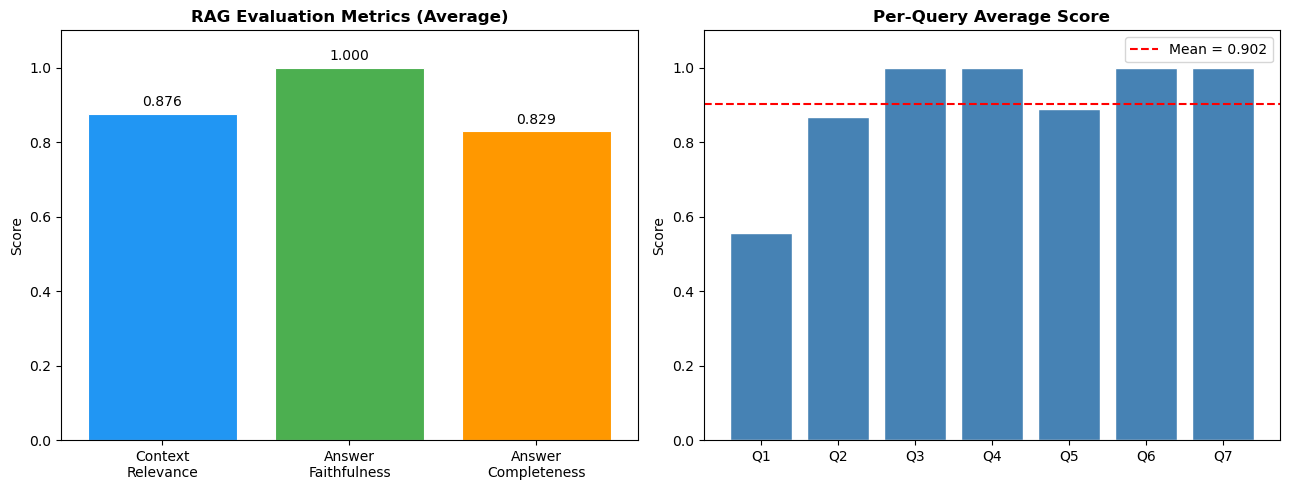

✅ Evaluation chart saved → rag_evaluation.png


In [19]:
# Evaluation charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
qs = [f'Q{i+1}' for i in range(len(eval_df))]

# Chart 1: Metric averages
metric_labels = ['Context\nRelevance','Answer\nFaithfulness','Answer\nCompleteness']
vals   = [eval_df['context_relevance'].mean(),
          eval_df['answer_faithfulness'].mean(),
          eval_df['answer_completeness'].mean()]
colors = ['#2196F3','#4CAF50','#FF9800']
axes[0].bar(metric_labels, vals, color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('RAG Evaluation Metrics (Average)', fontweight='bold')
axes[0].set_ylabel('Score')
for i, v in enumerate(vals):
    axes[0].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=10)

# Chart 2: Per-query avg score
axes[1].bar(qs, eval_df['avg_score'], color='steelblue', edgecolor='white')
axes[1].axhline(eval_df['avg_score'].mean(), color='red', linestyle='--',
                label=f'Mean = {eval_df["avg_score"].mean():.3f}')
axes[1].set_ylim(0, 1.1)
axes[1].set_title('Per-Query Average Score', fontweight='bold')
axes[1].set_ylabel('Score')
axes[1].legend()

plt.tight_layout()
plt.savefig('rag_evaluation.png', dpi=150)
plt.show()
print('✅ Evaluation chart saved → rag_evaluation.png')

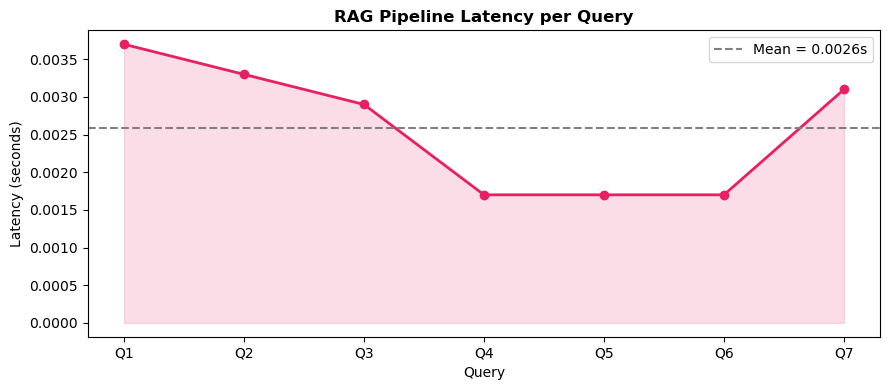

✅ Latency chart saved → rag_latency.png


In [20]:
# Latency chart
plt.figure(figsize=(9, 4))
plt.plot(qs, eval_df['latency_sec'], marker='o', color='#E91E63', linewidth=2)
plt.axhline(eval_df['latency_sec'].mean(), color='gray', linestyle='--',
            label=f'Mean = {eval_df["latency_sec"].mean():.4f}s')
plt.fill_between(qs, eval_df['latency_sec'], alpha=0.15, color='#E91E63')
plt.title('RAG Pipeline Latency per Query', fontweight='bold')
plt.xlabel('Query')
plt.ylabel('Latency (seconds)')
plt.legend()
plt.tight_layout()
plt.savefig('rag_latency.png', dpi=150)
plt.show()
print('✅ Latency chart saved → rag_latency.png')

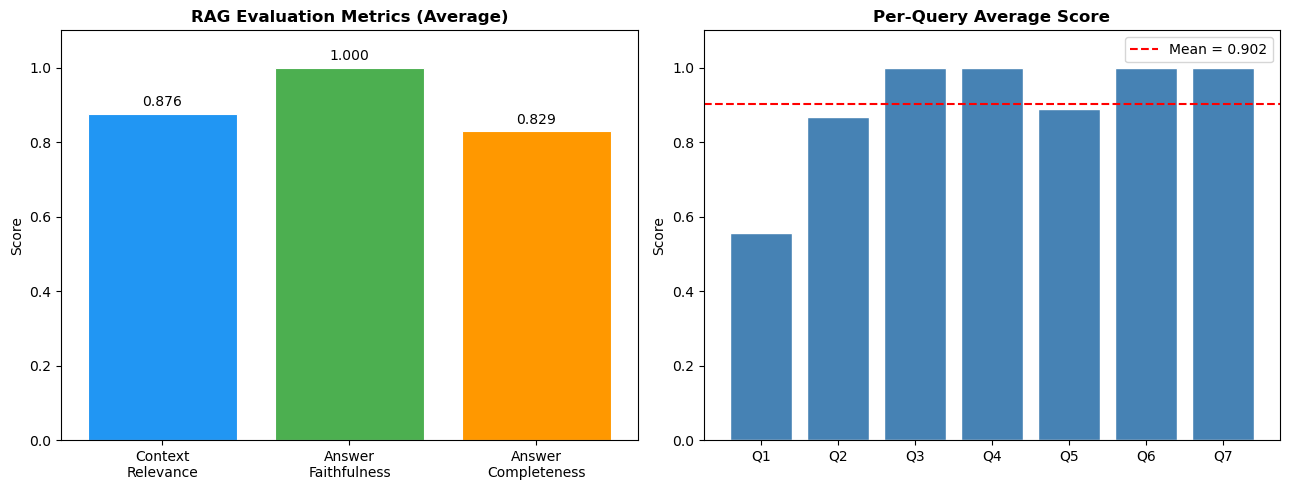

✅ Evaluation chart saved → rag_evaluation.png


In [21]:
# Evaluation charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
qs = [f'Q{i+1}' for i in range(len(eval_df))]

# Chart 1: Metric averages
metric_labels = ['Context\nRelevance','Answer\nFaithfulness','Answer\nCompleteness']
vals   = [eval_df['context_relevance'].mean(),
          eval_df['answer_faithfulness'].mean(),
          eval_df['answer_completeness'].mean()]
colors = ['#2196F3','#4CAF50','#FF9800']
axes[0].bar(metric_labels, vals, color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('RAG Evaluation Metrics (Average)', fontweight='bold')
axes[0].set_ylabel('Score')
for i, v in enumerate(vals):
    axes[0].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=10)

# Chart 2: Per-query avg score
axes[1].bar(qs, eval_df['avg_score'], color='steelblue', edgecolor='white')
axes[1].axhline(eval_df['avg_score'].mean(), color='red', linestyle='--',
                label=f'Mean = {eval_df["avg_score"].mean():.3f}')
axes[1].set_ylim(0, 1.1)
axes[1].set_title('Per-Query Average Score', fontweight='bold')
axes[1].set_ylabel('Score')
axes[1].legend()

plt.tight_layout()
plt.savefig('rag_evaluation.png', dpi=150)
plt.show()
print('✅ Evaluation chart saved → rag_evaluation.png')

In [22]:
# Log evaluation to MLflow
with mlflow.start_run(run_name='RAG_Evaluation_v1'):
    mlflow.log_metric('avg_context_relevance',   eval_df['context_relevance'].mean())
    mlflow.log_metric('avg_answer_faithfulness', eval_df['answer_faithfulness'].mean())
    mlflow.log_metric('avg_answer_completeness', eval_df['answer_completeness'].mean())
    mlflow.log_metric('overall_avg_score',       eval_df['avg_score'].mean())
    mlflow.log_metric('avg_latency_sec',         eval_df['latency_sec'].mean())
    eval_df.to_csv('rag_evaluation_results.csv', index=False)
    mlflow.log_artifact('rag_evaluation_results.csv')
    mlflow.log_artifact('rag_evaluation.png')
    mlflow.log_artifact('rag_latency.png')

print('✅ Evaluation metrics logged to MLflow')

✅ Evaluation metrics logged to MLflow


In [24]:
# Final summary
print('=' * 62)
print('              PART B — FINAL SUMMARY')
print('=' * 62)
print(f'  Knowledge base docs    : {len(raw_docs)}')
print(f'  Total chunks indexed   : {len(all_chunks)}')
print(f'  Embedding method       : TF-IDF (sklearn, offline)')
print(f'  Vector store           : FAISS IndexFlatIP')
print(f'  Test queries           : {len(test_queries)}')
print(f'  Avg Context Relevance  : {eval_df["context_relevance"].mean():.3f}')
print(f'  Avg Faithfulness       : {eval_df["answer_faithfulness"].mean():.3f}')
print(f'  Avg Completeness       : {eval_df["answer_completeness"].mean():.3f}')
print(f'  Overall RAG Score      : {eval_df["avg_score"].mean():.3f}')
print(f'  Avg Latency            : {eval_df["latency_sec"].mean():.4f}s')
print(f'  MLflow runs logged     : 3')
print('=' * 62)


              PART B — FINAL SUMMARY
  Knowledge base docs    : 9
  Total chunks indexed   : 26
  Embedding method       : TF-IDF (sklearn, offline)
  Vector store           : FAISS IndexFlatIP
  Test queries           : 7
  Avg Context Relevance  : 0.876
  Avg Faithfulness       : 1.000
  Avg Completeness       : 0.829
  Overall RAG Score      : 0.902
  Avg Latency            : 0.0026s
  MLflow runs logged     : 3
